In [23]:
# -*- coding: utf-8 -*-

In [70]:
import torch
from torch import nn
import numpy as np

In [71]:
from pathlib import Path
data_path =Path("data/")
image_path = data_path / "desert101"

In [72]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import json
import matplotlib.pyplot as plt

# Proje dizin yapınıza uygun olarak sonuç yollarını belirleyelim
results_path = Path("results")
metrics_dir = results_path / "metrics"
models_dir = results_path / "models"
plots_dir = results_path / "plots"

# Klasörler mevcut değilse otomatik oluşturalım
for dir_path in [metrics_dir, models_dir, plots_dir]:
    dir_path.mkdir(parents=True, exist_ok=True)

print(f"Kayıt dizinleri hazır: {results_path}")

Kayıt dizinleri hazır: results


In [73]:
def save_experiment_results(experiment_name, model, history, hyperparameters):
    """
    experiment_name: str (örn: 'transform_v1_lr_0.001', 'transform_v2_normalization')
    model: torch.nn.Module (Eğitilen model)
    history: dict (Epoch bazlı loss ve accuracy değerleri listesi)
    hyperparameters: dict (Öğrenme oranı, batch size, transform detayları vb.)
    """
    # 1. Modeli kaydet
    model_filepath = models_dir / f"{experiment_name}.pth"
    torch.save(model.state_dict(), model_filepath)

    # 2. Metrikleri ve hiperparametreleri JSON olarak kaydet
    experiment_data = {
        "hyperparameters": hyperparameters,
        "history": history
    }
    metrics_filepath = metrics_dir / f"{experiment_name}_metrics.json"
    with open(metrics_filepath, "w", encoding="utf-8") as f:
        json.dump(experiment_data, f, indent=4)

    # 3. Eğitim ve Test grafiklerini çizip kaydet
    plt.figure(figsize=(12, 5))

    # Loss Grafiği
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['test_loss'], label='Test Loss')
    plt.title(f"Loss - {experiment_name}")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy Grafiği
    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train Acc')
    plt.plot(history['test_acc'], label='Test Acc')
    plt.title(f"Accuracy - {experiment_name}")
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plot_filepath = plots_dir / f"{experiment_name}_plot.png"
    plt.savefig(plot_filepath, dpi=300, bbox_inches='tight')
    plt.close()

    print(f"'{experiment_name}' için tüm sonuçlar başarıyla kaydedildi!")

In [74]:
image_path

WindowsPath('data/desert101')

In [75]:
import os

In [76]:
def check_data(dir_path):
    for dirpath, dirnames,filenames in os.walk(dir_path):
        print(f"# of directories : {len(dirnames)} and {len(filenames)} images in {dirpath}")

In [77]:
check_data(image_path)

# of directories : 2 and 0 images in data\desert101
# of directories : 4 and 0 images in data\desert101\test
# of directories : 0 and 19 images in data\desert101\test\baklava
# of directories : 0 and 19 images in data\desert101\test\cannoli
# of directories : 0 and 20 images in data\desert101\test\cup_cakes
# of directories : 0 and 19 images in data\desert101\test\donuts
# of directories : 4 and 0 images in data\desert101\train
# of directories : 0 and 79 images in data\desert101\train\baklava
# of directories : 0 and 79 images in data\desert101\train\cannoli
# of directories : 0 and 79 images in data\desert101\train\cup_cakes
# of directories : 0 and 79 images in data\desert101\train\donuts


In [78]:
train_dir = image_path / "train"
test_dir = image_path / "test"

In [79]:
train_dir

WindowsPath('data/desert101/train')

In [80]:
test_dir

WindowsPath('data/desert101/test')

In [81]:
from PIL import Image
import random

In [82]:
random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg"))
random_image = random.choice(image_path_list)
img = Image.open(random_image)

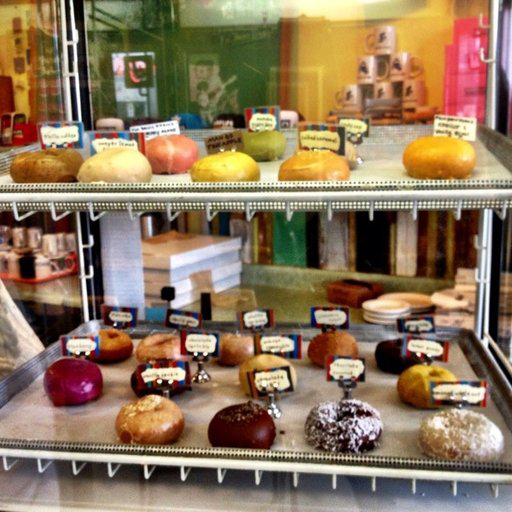

In [83]:
img

In [216]:
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [237]:
# 1. TRAIN İÇİN TRANSFORMLAR (Veri Artırma DAHİL)
train_transforms = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.4),
    #transforms.RandomVerticalFlip(p=0.4),
    #transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.3),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5482, 0.4636, 0.3866], std=[0.254, 0.2574, 0.2628])
])

# 2. TEST İÇİN TRANSFORMLAR (Sadece Zorunlu İşlemler)
test_transforms = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5482, 0.4636, 0.3866], std=[0.254, 0.2574, 0.2628])
])

In [238]:
train_data = datasets.ImageFolder(root=train_dir,
                                  transform=train_transforms,
)
test_data = datasets.ImageFolder(root=test_dir,
                                  transform=test_transforms,
)

In [239]:
train_data

Dataset ImageFolder
    Number of datapoints: 316
    Root location: data\desert101\train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.4)
               TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
               ToTensor()
               Normalize(mean=[0.5482, 0.4636, 0.3866], std=[0.254, 0.2574, 0.2628])
           )

In [240]:
test_data

Dataset ImageFolder
    Number of datapoints: 77
    Root location: data\desert101\test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.5482, 0.4636, 0.3866], std=[0.254, 0.2574, 0.2628])
           )

In [241]:
class_names = train_data.classes

In [242]:
len(train_data),len(test_data)

(316, 77)

In [243]:
BATCH_SİZE = 32
NUM_WORKERS = 12 #os.cpu_count()

In [244]:
NUM_WORKERS

12

In [245]:
train_dataloader = DataLoader(dataset = train_data,
                              batch_size=BATCH_SİZE,
                              num_workers=12,
                              shuffle=True)

test_datalaoder = DataLoader( dataset= test_data,
                             batch_size=BATCH_SİZE,
                             num_workers=12,
                             shuffle=False)

In [246]:
train_dataloader.dataset[0][0]

tensor([[[-2.0811, -2.0965, -2.0502,  ..., -1.9576, -1.8186, -1.7877],
         [-2.0656, -2.0965, -1.9576,  ..., -2.0039, -1.9112, -1.6333],
         [-1.9267, -2.0656, -1.8340,  ..., -1.8958, -1.9421, -1.4017],
         ...,
         [-0.4445, -0.1512, -0.0122,  ...,  1.5472,  1.4545,  1.2847],
         [-0.1975, -0.3982, -0.5217,  ...,  1.6398,  1.5935,  1.2384],
         [-0.2284,  0.1885, -0.0122,  ...,  1.3156,  1.3928,  1.2075]],

        [[-1.6640, -1.6640, -1.6183,  ..., -1.5116, -1.3440, -1.3288],
         [-1.6183, -1.6487, -1.5269,  ..., -1.5421, -1.4659, -1.0393],
         [-1.5269, -1.6335, -1.4354,  ..., -1.4659, -1.4811, -0.7041],
         ...,
         [-0.9784, -0.7041, -0.4604,  ...,  1.7487,  1.4288,  0.8042],
         [-0.6584, -0.7499, -0.8565,  ...,  1.7792,  1.7335,  0.9565],
         [-0.4299,  0.0576, -0.0947,  ...,  1.3831,  1.3831,  0.8042]],

        [[-1.2622, -1.2771, -1.2174,  ..., -0.5459,  0.1704,  0.1107],
         [-1.1129, -1.1876, -0.7847,  ..., -0

In [247]:
class DesertClassifier(nn.Module):
    def __init__(self, input_shape : int , hidde_units : int, output_shape : int):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
             nn.Conv2d(in_channels=input_shape,
                      out_channels=hidde_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidde_units,
                      out_channels=hidde_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )
        self.conv_block_2 = nn.Sequential(
             nn.Conv2d(in_channels=hidde_units,
                      out_channels=hidde_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidde_units,
                      out_channels=hidde_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(in_features=hidde_units * 16 *16,
                     out_features=output_shape)
        )
    def forward(self,x):
        return self.classifier(self.conv_block_2(self.conv_block_1(x))) 

In [248]:
model_0 = DesertClassifier(input_shape=3,
                           hidde_units=128,
                           output_shape=len(class_names))

In [249]:
from torchinfo import summary

In [250]:
summary(model_0,input_size=[1,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
DesertClassifier                         [1, 4]                    --
├─Sequential: 1-1                        [1, 128, 32, 32]          --
│    └─Conv2d: 2-1                       [1, 128, 64, 64]          3,584
│    └─ReLU: 2-2                         [1, 128, 64, 64]          --
│    └─Conv2d: 2-3                       [1, 128, 64, 64]          147,584
│    └─ReLU: 2-4                         [1, 128, 64, 64]          --
│    └─MaxPool2d: 2-5                    [1, 128, 32, 32]          --
├─Sequential: 1-2                        [1, 128, 16, 16]          --
│    └─Conv2d: 2-6                       [1, 128, 32, 32]          147,584
│    └─ReLU: 2-7                         [1, 128, 32, 32]          --
│    └─Conv2d: 2-8                       [1, 128, 32, 32]          147,584
│    └─ReLU: 2-9                         [1, 128, 32, 32]          --
│    └─MaxPool2d: 2-10                   [1, 128, 16, 16]          

In [251]:
def train_step ( model: torch.nn.Module, dataloader : torch.utils.data.DataLoader,
                loss_fn: torch.nn.Module, optimizer: torch.optim.Optimizer):
    model.train()

    train_loss = 0
    train_acc = 0

    for batch, (X,y) in enumerate(dataloader):

        y_pred = model(X)
        loss = loss_fn(y_pred,y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_class = torch.argmax(torch.softmax(y_pred,dim=1),dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [252]:
def test_step(model: torch.nn.Module, dataloader: torch.utils.data.DataLoader,
             loss_fn: torch.nn.Module):
    model.eval()
    test_loss = 0
    test_acc = 0

    with torch.inference_mode():
        for batch, (X,y) in enumerate(dataloader):
            test_pred_logits = model(X)
            loss = loss_fn(test_pred_logits,y)
            test_loss += loss.item()

            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += (test_pred_labels == y).sum().item() / len(test_pred_labels)
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss , test_acc

In [253]:
def train( model: torch.nn.Module, 
           train_dataloader : torch.utils.data.DataLoader,
           test_dataloader : torch.utils.data.DataLoader,
           optimizer: torch.optim.Optimizer,
           loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
           epochs : int = 10):
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}

    for epoch in range(epochs):
        train_loss,train_acc = train_step(model=model,
                                          dataloader=train_dataloader,
                                          loss_fn=loss_fn,
                                          optimizer=optimizer)
        test_loss,test_acc = test_step(model=model,
                                          dataloader=test_dataloader,
                                          loss_fn=loss_fn)

        print(f"Epoch: {epoch}, Train Loss: {train_loss}, Train Acc: {train_acc}, Test Loss: {test_loss}, Test Acc: {test_acc}")

        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc) 
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)
    return results

In [254]:
EPOCHS = 20
model_0 = DesertClassifier(input_shape=3,
                           hidde_units=128,
                           output_shape=len(class_names))

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.0005,weight_decay=1e-4)

model_0_results = train(model=model_0,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_datalaoder,
                       loss_fn=loss_fn,
                       optimizer=optimizer,
                       epochs=EPOCHS)

Epoch: 0, Train Loss: 1.3960731983184815, Train Acc: 0.24241071428571428, Test Loss: 1.3461430072784424, Test Acc: 0.4334935897435897
Epoch: 1, Train Loss: 1.3645455360412597, Train Acc: 0.34910714285714284, Test Loss: 1.3744252522786458, Test Acc: 0.2860576923076923
Epoch: 2, Train Loss: 1.2955102324485779, Train Acc: 0.3875, Test Loss: 1.2868277231852214, Test Acc: 0.327724358974359
Epoch: 3, Train Loss: 1.2996444940567016, Train Acc: 0.38392857142857145, Test Loss: 1.2524861494700115, Test Acc: 0.4463141025641026
Epoch: 4, Train Loss: 1.267479407787323, Train Acc: 0.4321428571428571, Test Loss: 1.3438127040863037, Test Acc: 0.3125
Epoch: 5, Train Loss: 1.263043749332428, Train Acc: 0.4125, Test Loss: 1.2418301502863567, Test Acc: 0.3790064102564103
Epoch: 6, Train Loss: 1.2058597445487975, Train Acc: 0.453125, Test Loss: 1.2228291829427083, Test Acc: 0.4054487179487179
Epoch: 7, Train Loss: 1.1885397970676421, Train Acc: 0.4790178571428571, Test Loss: 1.3234405517578125, Test Acc: 0

In [255]:
# Deney ismini yaptığınız değişikliğe göre her seferinde manuel güncelleyin
experiment_id = "transform_v4_hidden_128_weight_decay_eklendi"

# Eğitim fonksiyonundan (train) dönen sonuçları bağlama
history_data = {
    "train_loss": model_0_results["train_loss"],
    "test_loss": model_0_results["test_loss"],
    "train_acc": model_0_results["train_acc"],
    "test_acc": model_0_results["test_acc"]
}

# O an denediğiniz parametreler (DİNAMİK HALE GETİRİLDİ)
current_hyperparams = {
    "learning_rate": optimizer.param_groups[0]['lr'],
    "weight_decay": optimizer.param_groups[0]['weight_decay'],
    "batch_size": BATCH_SİZE,
    "train_transforms": repr(train_transforms),
    "test_transforms": repr(test_transforms),
    "epochs": EPOCHS,
    "device": "cpu",
    "optimizer": "Adam",
    "loss_fn": repr(loss_fn), # DİREK DEĞİŞKEN YAZDIRALAMAZ REPR İLE STR ÇEVRİLİR
    "hidden_units": 128
}

# Otomatik olarak kaydetmeyi tetikle
save_experiment_results(experiment_id, model_0, history_data, current_hyperparams)

'transform_v4_hidden_128_weight_decay_eklendi' için tüm sonuçlar başarıyla kaydedildi!


In [32]:
model_0_result_yedek=model_0_results

In [33]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import matplotlib.pyplot as plt
%matplotlib inline

In [34]:
def plot_loss_curves(results):
    loss = results["train_loss"]
    test_loss = results["test_loss"]
    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(16,8))

    plt.subplot(1,2,1)
    plt.plot(epochs, loss,label ="Train_loss")
    plt.plot(epochs,test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, accuracy,label ="Train_accuracy")
    plt.plot(epochs,test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

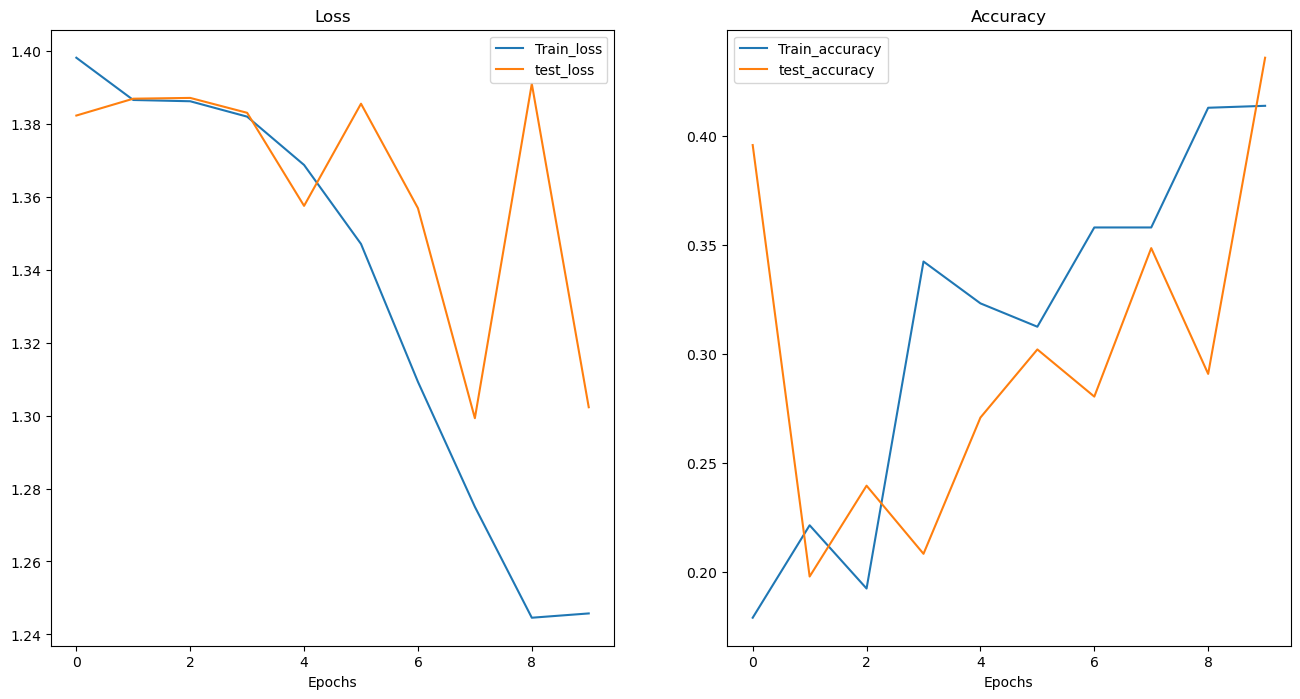

In [35]:
plot_loss_curves(model_0_results)

In [36]:
def make_predictions(model: torch.nn.Module, data: list):
    """
    data: [img_tensor, img_tensor, ...]  # her biri [C, H, W]
    return: [N, num_classes] olasılık tensörü
    """
    pred_probs = []
    model.eval()

    with torch.inference_mode():
        for sample in data:
            # [C, H, W] -> [1, C, H, W]
            sample = sample.unsqueeze(0)

            # Logits al
            pred_logit = model(sample)    # shape: [1, num_classes]

            # Softmax ile olasılığa çevir
            prob = torch.softmax(pred_logit, dim=1)  # [1, num_classes]

            # Batch boyutunu sıkıştır
            pred_probs.append(prob.squeeze(0))       # [num_classes]

    # Hepsini birleştir → [N, num_classes]
    return torch.stack(pred_probs)

In [37]:
def show_random_predictions(model, dataset, class_names, n=9):
    model.eval()
    
    plt.figure(figsize=(4, 4))

    # random 9 index seç
    indices = random.sample(range(len(dataset)), n)

    with torch.inference_mode():
        for i, idx in enumerate(indices):
            img, true_label = dataset[idx]

            # modele uygun hale getir
            img_input = img.unsqueeze(0)  
            logits = model(img_input)
            pred_label = logits.argmax(dim=1).item()

            # görseli çizmek için permute
            img_show = img.permute(1, 2, 0)

            # doğru mu yanlış mı?
            correct = (pred_label == true_label)
            color = "green" if correct else "red"

            # subplot
            plt.subplot(3, 3, i + 1)
            plt.imshow(img_show)
            plt.axis("off")

            plt.title(
                f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",
                color=color,
                fontsize=10
            )

    plt.tight_layout()
    plt.show()

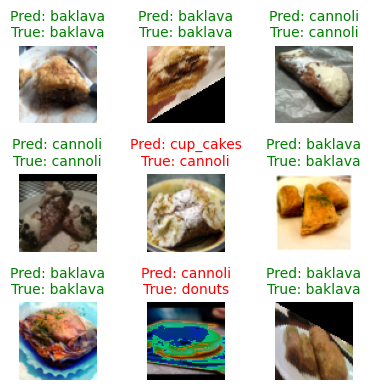

In [38]:
show_random_predictions(model_0, test_data, class_names)

In [39]:
online_image_path = data_path / "baklava.jpg"

In [40]:
import torchvision

In [41]:
single_image= torchvision.io.read_image(str(online_image_path))

In [42]:
single_image

tensor([[[129, 130, 132,  ...,  27,  27,  27],
         [129, 130, 132,  ...,  27,  27,  27],
         [129, 130, 133,  ...,  27,  27,  27],
         ...,
         [ 29,  29,  29,  ...,  54,  54,  54],
         [ 32,  32,  32,  ...,  56,  56,  56],
         [ 43,  42,  42,  ...,  66,  66,  66]],

        [[116, 117, 119,  ...,  29,  29,  29],
         [116, 117, 119,  ...,  29,  29,  29],
         [116, 117, 118,  ...,  29,  29,  29],
         ...,
         [ 31,  31,  31,  ...,  55,  55,  55],
         [ 34,  34,  34,  ...,  57,  57,  57],
         [ 45,  44,  44,  ...,  67,  67,  67]],

        [[ 22,  23,  23,  ...,  28,  28,  28],
         [ 22,  23,  23,  ...,  28,  28,  28],
         [ 22,  23,  23,  ...,  28,  28,  28],
         ...,
         [ 28,  28,  28,  ...,  50,  50,  50],
         [ 31,  31,  31,  ...,  52,  52,  52],
         [ 42,  41,  41,  ...,  62,  62,  62]]], dtype=torch.uint8)

In [43]:
single_image = single_image /255

In [44]:
single_image

tensor([[[0.5059, 0.5098, 0.5176,  ..., 0.1059, 0.1059, 0.1059],
         [0.5059, 0.5098, 0.5176,  ..., 0.1059, 0.1059, 0.1059],
         [0.5059, 0.5098, 0.5216,  ..., 0.1059, 0.1059, 0.1059],
         ...,
         [0.1137, 0.1137, 0.1137,  ..., 0.2118, 0.2118, 0.2118],
         [0.1255, 0.1255, 0.1255,  ..., 0.2196, 0.2196, 0.2196],
         [0.1686, 0.1647, 0.1647,  ..., 0.2588, 0.2588, 0.2588]],

        [[0.4549, 0.4588, 0.4667,  ..., 0.1137, 0.1137, 0.1137],
         [0.4549, 0.4588, 0.4667,  ..., 0.1137, 0.1137, 0.1137],
         [0.4549, 0.4588, 0.4627,  ..., 0.1137, 0.1137, 0.1137],
         ...,
         [0.1216, 0.1216, 0.1216,  ..., 0.2157, 0.2157, 0.2157],
         [0.1333, 0.1333, 0.1333,  ..., 0.2235, 0.2235, 0.2235],
         [0.1765, 0.1725, 0.1725,  ..., 0.2627, 0.2627, 0.2627]],

        [[0.0863, 0.0902, 0.0902,  ..., 0.1098, 0.1098, 0.1098],
         [0.0863, 0.0902, 0.0902,  ..., 0.1098, 0.1098, 0.1098],
         [0.0863, 0.0902, 0.0902,  ..., 0.1098, 0.1098, 0.

Text(0.5, 1.0, 'torch.Size([3, 3000, 4000])')

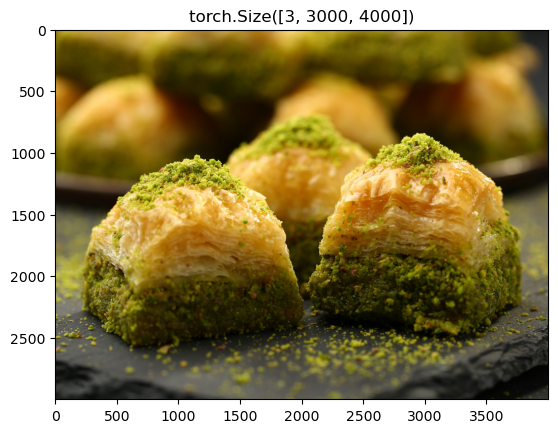

In [45]:
plt.imshow(single_image.permute(1,2,0))
plt.title(single_image.shape)

In [46]:
single_image_transform = transforms.Compose([
    transforms.Resize(size=(64,64))
])
single_image = single_image_transform(single_image)

In [47]:
single_image.shape

torch.Size([3, 64, 64])

In [48]:
single_image.unsqueeze(dim=0).shape

torch.Size([1, 3, 64, 64])

In [49]:
single_image=single_image.unsqueeze(dim=0)

In [53]:
model_0.eval()
with torch.inference_mode():
    logits = model_0(single_image)
    probs = torch.softmax(logits,dim=1)
    pred_idx = probs.argmax(dim=1).item()
print("Predicted class : ", class_names[pred_idx])

Predicted class :  baklava
